In [2]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [3]:
data = pd.read_parquet("../data/shots_curated.parquet")

In [4]:
obj_cols = ['shot_body_part', 'shot_type', 'shot_technique', 'play_pattern']

preprocessor = ColumnTransformer(
    transformers = [
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), obj_cols)
    ],
    remainder='passthrough'
)

data_encoded = preprocessor.fit_transform(data)

In [5]:
data_encoded

array([[0.0, 0.0, 0.0, ..., 0, 18.66976164818394, 0.3030903140522431],
       [0.0, 0.0, 0.0, ..., 0, 23.500212764994277, 0.3371880572249301],
       [0.0, 0.0, 0.0, ..., 0, 32.27212419410907, 0.24316752002276612],
       ...,
       [0.0, 0.0, 0.0, ..., 0, 26.622171211229183, 0.24336804120155203],
       [0.0, 0.0, 0.0, ..., 0, 22.48488381112964, 0.27247903128273365],
       [0.0, 0.0, 0.0, ..., 0, 23.93532953606446, 0.14408347518588693]],
      shape=(99746, 33), dtype=object)

In [6]:
cols = preprocessor.get_feature_names_out()
final_df = pd.DataFrame(data_encoded, columns=cols)

In [7]:
from sklearn.model_selection import GroupShuffleSplit

for col in final_df.select_dtypes(include=['object', 'category']).columns:
    final_df[col] = final_df[col].astype('int', errors='ignore')
X = final_df.drop(columns=['remainder__target'])
y = final_df['remainder__target']

groups = final_df['remainder__match_id']

C:\Users\denze\AppData\Local\Temp\ipykernel_23700\2779994511.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in final_df.select_dtypes(include=['object', 'category']).columns:


In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)

train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [9]:
X_train.shape, X_test.shape

((74878, 32), (24868, 32))

In [10]:
from xgboost import XGBClassifier

model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

model.fit(X_train.drop(columns=['remainder__id', 'remainder__match_id']), y_train)

probs = model.predict_proba(X_test.drop(columns=['remainder__id', 'remainder__match_id']))

In [11]:
probs_1 = probs[:,1]

In [12]:
probs_1[:5]

array([0.07024951, 0.12276102, 0.01920854, 0.04096127, 0.15063098],
      dtype=float32)

In [13]:
from sklearn.metrics import log_loss, precision_recall_curve, roc_auc_score

auc = roc_auc_score(y_test, probs_1)
loss = log_loss(y_test, probs_1)
precision, recall, tresholds = precision_recall_curve(y_test, probs_1)

print(f"ROC AUC score: {auc:.4f}")
print(f"Log loss: {loss:.4f}")

ROC AUC score: 0.7850
Log loss: 0.2755


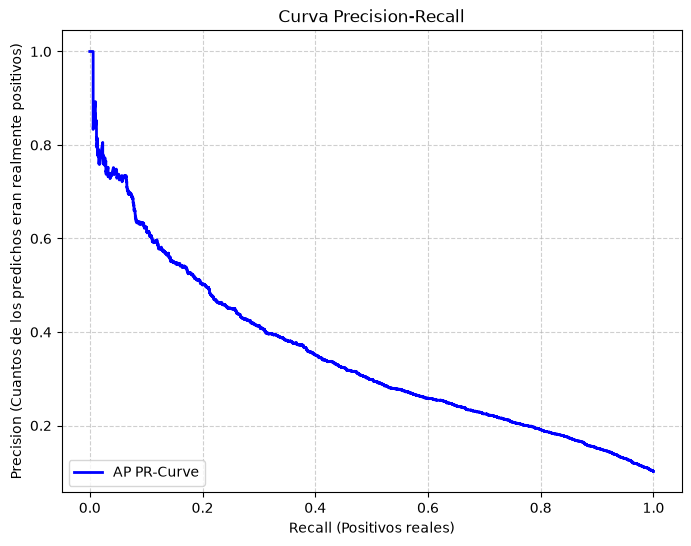

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.plot(
    recall, precision, color='b', lw=2, label='AP PR-Curve'
)
plt.xlabel("Recall (Positivos reales)")
plt.ylabel("Precision (Cuantos de los predichos eran realmente positivos)")
plt.title('Curva Precision-Recall')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.show()

In [15]:
import numpy as np


# Compute log loss manually for one data point
def func_log_loss(p, y) -> float:
    return -((y*np.log(p)) + (1 - y)*(np.log(1-p)))

loss_dp = func_log_loss(probs_1[0], y_test.loc[0])

print(loss_dp)



KeyError: 0

In [ ]:
def calculate_base_log_loss(y_test):
    y = np.array(y_test)

    p = np.mean(y)

    if p==0 or p == 1:
        return 0.0

    entropy = -(p * np.log(p) + (1-p) * np.log(1-p))
    return entropy

baseline_loss = calculate_base_log_loss(y_test)
print(f'Log Loss Base Calculado: {baseline_loss:.4f}')


Log Loss Base Calculado: 0.3286
